# Практика 5: benchmarking baselines и выбор схемы валидации

**Цель:** построить baselines (Naive, Seasonal Naive, Mean, Drift, Theta), корректно сравнить их по нескольким метрикам, организовать backtesting (expanding и sliding window) и убедиться, что схема валидации не даёт утечек.

**Данные.** Дневной ряд за 2 года ($N=730$) с трендом, недельной сезонностью ($s=7$) и шумом. Строим его генератором из ЛР 1:

1. `generate_time_series(trend="slow_up", seasonality="one", noise_std=2)` даёт $100 + 30\,t/(N-1) + 10\sin(2\pi i/7) + \varepsilon_i$. В ЛР 1 период `one` равен 12 точкам (шаг 5 минут), здесь для дневных данных переопределяем `PERIOD_1H = 7`;
2. добавляем автокоррелированную компоненту AR(1): $u_t = 0{,}8\,u_{t-1} + \eta_t$, $\eta_t\sim N(0,2^2)$. Это нужно, чтобы ряд был похож на реальные продажи (спрос «держится» несколько дней) и чтобы утечка в шаге 6 была видна. Без неё шум независим и случайный split почти ничего не портит.

**Параметры.** Горизонт $H=7$, число тестовых фолдов $K=10$ (последние 70 дней), окно sliding $L=28$ (4 недели).


## 0. Импорт и генератор из ЛР 1

In [ ]:
import warnings
from datetime import datetime, date, time, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore")

# ---- генератор из ЛР 1 (без сохранения в файлы) ----
STEP = timedelta(minutes=5)
VARIANCE_MODES = ("const", "grow", "decay")
TREND_MODES = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
EXTRA_TREND_MODES = ("exp", "poly", "log")
SEASONALITY_MODES = ("none", "one", "two")
PERIOD_1H = 12
PERIOD_6H = 72
TREND_DELTA = {"fast_up": 150.0, "slow_up": 30.0, "fast_down": -150.0, "slow_down": -30.0}


def make_timestamps(n_points, start=None):
    if start is None:
        start = datetime.combine(date.today(), time.min)
    return [start + i * STEP for i in range(n_points)]


def make_variance(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "const":
        return np.ones(n_points)
    if mode == "grow":
        return 0.5 + 4.5 * t
    if mode == "decay":
        return 5.0 - 4.5 * t
    raise ValueError(f"Неизвестный режим дисперсии: {mode}")


def make_trend(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode in TREND_DELTA:
        return TREND_DELTA[mode] * t
    if mode == "exp":
        return 100.0 * (np.exp(3.0 * t) - 1.0) / (np.exp(3.0) - 1.0)
    if mode == "poly":
        return 100.0 * (t ** 3 - 1.5 * t ** 2 + t)
    if mode == "log":
        return 100.0 * np.log1p(20.0 * t) / np.log1p(20.0)
    raise ValueError(f"Неизвестный режим тренда: {mode}")


def make_seasonality(mode, n_points):
    i = np.arange(n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode == "one":
        return 10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
    if mode == "two":
        return (10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
                + 20.0 * np.sin(2 * np.pi * i / PERIOD_6H))
    raise ValueError(f"Неизвестный режим сезонности: {mode}")


def generate_time_series(n_points=1000, variance="random", trend="random",
                         seasonality="random", base=100.0, noise_std=1.0, seed=None,
                         outliers=0, missing=0.0, start=None):
    rng = np.random.default_rng(seed)
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    timestamps = make_timestamps(n_points, start)
    noise = rng.normal(0.0, noise_std, n_points) * make_variance(variance, n_points)
    values = base + make_trend(trend, n_points) + make_seasonality(seasonality, n_points) + noise

    outlier_idx = []
    if outliers > 0:
        outlier_idx = rng.choice(n_points, size=min(outliers, n_points), replace=False)
        scale = np.std(values) * 3
        values[outlier_idx] += rng.choice([-1, 1], size=len(outlier_idx)) * scale
        outlier_idx = sorted(int(k) for k in outlier_idx)

    missing_idx = []
    if missing > 0:
        k = int(round(n_points * missing))
        missing_idx = rng.choice(n_points, size=k, replace=False)
        values[missing_idx] = np.nan
        missing_idx = sorted(int(k) for k in missing_idx)

    params = {"n_points": n_points, "step_minutes": 5,
              "start": timestamps[0].strftime("%Y-%m-%d %H:%M:%S"),
              "variance": variance, "trend": trend, "seasonality": seasonality,
              "base": base, "noise_std": noise_std, "seed": seed,
              "outliers": outlier_idx, "missing_count": len(missing_idx)}
    return timestamps, values, params

## 1. Данные

{'n_points': 730, 'step_minutes': 5, 'start': '2023-01-02 00:00:00', 'variance': 'const', 'trend': 'slow_up', 'seasonality': 'one', 'base': 100.0, 'noise_std': 2.0, 'seed': 7, 'outliers': [], 'missing_count': 0}
n = 730, y_min = 86.8, y_max = 141.8 (нулей нет, MAPE определён)
тестовых фолдов: 10, первый origin = 660 (2024-10-23), последний тест заканчивается 2024-12-31


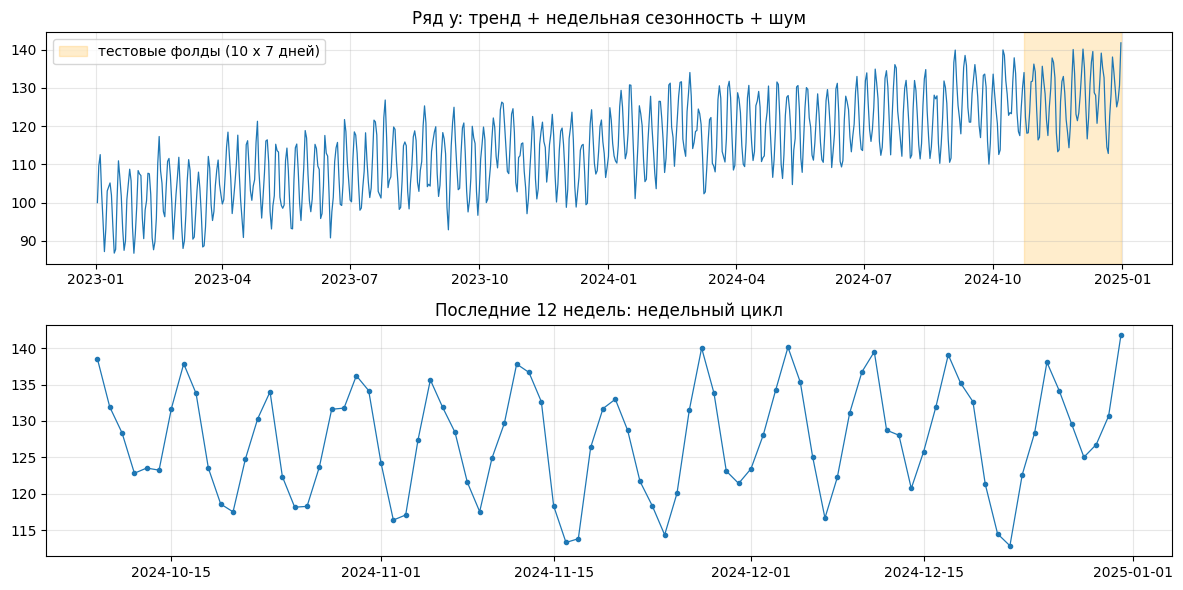

In [ ]:
PERIOD_1H = 7                       # «one» = недельная сезонность (для дневных данных; в ЛР 1 было 12 точек)
N, S, H, K, L = 730, 7, 7, 10, 28   # длина ряда, период, горизонт, число фолдов, окно sliding (4 недели)
idx = pd.date_range("2023-01-02", periods=N, freq="D")        # 2 года, начало в понедельник

NOISE_STD = 2.0
ts, vals, params = generate_time_series(
    n_points=N, variance="const", trend="slow_up", seasonality="one",
    base=100.0, noise_std=NOISE_STD, seed=7, start=datetime(2023, 1, 2))
print(params)

# автокоррелированная компонента AR(1)
PHI, SIG = 0.8, 2.0
rng = np.random.default_rng(2023)
u = np.zeros(N)
for t in range(1, N):
    u[t] = PHI * u[t - 1] + rng.normal(0.0, SIG)

y = pd.Series(np.asarray(vals) + u, index=idx, name="y")
yv = y.to_numpy()
FIRST = N - K * H                    # первая точка отсчёта тестовых фолдов
ORIGINS = list(range(FIRST, N - H + 1, H))
print(f"n = {N}, y_min = {y.min():.1f}, y_max = {y.max():.1f} (нулей нет, MAPE определён)")
print(f"тестовых фолдов: {len(ORIGINS)}, первый origin = {FIRST} ({idx[FIRST].date()}), последний тест заканчивается {idx[-1].date()}")

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(y.index, y, lw=0.9)
axes[0].axvspan(idx[FIRST], idx[-1], color="orange", alpha=0.2, label="тестовые фолды (10 x 7 дней)")
axes[0].set_title("Ряд y: тренд + недельная сезонность + шум"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(y.index[-84:], y.iloc[-84:], marker="o", ms=3, lw=0.9)
axes[1].set_title("Последние 12 недель: недельный цикл"); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 2. Метрики

Для ошибки $e_t = y_t - \hat y_t$ на тестовых точках:

$$\mathrm{MAE}=\frac1m\sum|e_t|,\quad \mathrm{RMSE}=\sqrt{\frac1m\sum e_t^2},\quad \mathrm{MAPE}=\frac{100}{m}\sum\frac{|e_t|}{|y_t|},\quad \mathrm{sMAPE}=\frac{100}{m}\sum\frac{2|e_t|}{|y_t|+|\hat y_t|},$$

$$\mathrm{MASE}=\frac{\mathrm{MAE}}{\frac{1}{n-s}\sum_{t=s+1}^{n}|y_t-y_{t-s}|}\quad(s=7).$$

MAPE: она делится на $y_t$ и взрывается при значениях около нуля, а ещё штрафует завышение и занижение несимметрично. У нас $y\approx 90\text{–}150$, поэтому MAPE определена. MASE масштабируется MAE сезонного наива **на обучающей части**. Чтобы MASE был сопоставим между схемами и фолдами, знаменатель считаем один раз по $y[:\text{FIRST}]$ (данные до первого тестового фолда).

In [ ]:
def mae(t, p):
    return float(np.mean(np.abs(np.asarray(t) - np.asarray(p))))


def rmse(t, p):
    return float(np.sqrt(np.mean((np.asarray(t) - np.asarray(p)) ** 2)))


def mape(t, p):
    t = np.asarray(t); return float(np.mean(np.abs(t - p) / np.abs(t)) * 100)


def smape(t, p):
    t = np.asarray(t); p = np.asarray(p)
    return float(np.mean(2 * np.abs(t - p) / (np.abs(t) + np.abs(p))) * 100)


def mase(y_true, y_pred, y_train, season=1):
    y_train = np.asarray(y_train, float)
    naive_mae = np.mean(np.abs(y_train[season:] - y_train[:-season]))
    return float(np.mean(np.abs(np.asarray(y_true) - y_pred)) / naive_mae)


SCALE = np.mean(np.abs(yv[:FIRST][S:] - yv[:FIRST][:-S]))
print(f"знаменатель MASE (MAE сезонного наива на y[:{FIRST}], s={S}) = {SCALE:.3f}")

знаменатель MASE (MAE сезонного наива на y[:660], s=7) = 3.654


## 3. Baselines

| модель | прогноз на $h=1..H$ |
|---|---|
| Naive | $\hat y_{T+h}=y_T$ |
| Seasonal Naive | $\hat y_{T+h}=y_{T+h-s\lceil h/s\rceil}$ (значение того же дня недели) |
| Mean | $\hat y_{T+h}=\bar y$ |
| Drift | $\hat y_{T+h}=y_T+h\,\dfrac{y_T-y_1}{T-1}$ |
| Theta | сезонная поправка + SES + половина наклона линейного тренда |

Theta (Хайндман–Биллах): $\hat y_{T+h}=\ell_T+\dfrac{b_0}{2}\Big(h-1+\dfrac1\alpha-\dfrac{(1-\alpha)^T}{\alpha}\Big)$, где $\ell_T$ уровень SES, $b_0$ наклон МНК-прямой. Перед этим ряд очищается от недельной сезонности (аддитивные индексы по классической декомпозиции), после прогноза индексы возвращаются.

In [ ]:
def naive(train, H):
    return np.repeat(train[-1], H)


def seasonal_naive(train, H, s=7):
    last_season = train[-s:]
    reps = int(np.ceil(H / s))
    return np.tile(last_season, reps)[:H]


def mean_fc(train, H):
    return np.repeat(np.mean(train), H)


def drift(train, H):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, H + 1)


def seasonal_indices(x, s):
    # аддитивные сезонные индексы: x - центрированное скользящее среднее, усреднённое по фазе
    n = len(x)
    w = np.ones(s) / s if s % 2 == 1 else np.r_[0.5, np.ones(s - 1), 0.5] / s
    trend = np.convolve(x, w, mode="valid")
    off = (len(w) - 1) // 2
    detr = x[off:off + len(trend)] - trend
    phase = np.arange(off, off + len(trend)) % s
    si = np.array([detr[phase == k].mean() for k in range(s)])
    return si - si.mean()                                   # индекс фазы k = позиции k (mod s) от начала train


def ses_fit(x, grid=np.linspace(0.05, 1.0, 39)):
    # простое экспоненциальное сглаживание: alpha по сетке (минимум суммы квадратов одношаговых ошибок)
    best = (np.inf, None, None)
    for a in grid:
        lvl, sse = x[0], 0.0
        for v in x[1:]:
            e = v - lvl; sse += e * e; lvl += a * e
        if sse < best[0]:
            best = (sse, a, lvl)
    return best[1], best[2]


def theta(train, H, s=7):
    x = np.asarray(train, float); n = len(x)
    si = seasonal_indices(x, s) if n >= 2 * s else np.zeros(s)
    xa = x - si[np.arange(n) % s]
    alpha, level = ses_fit(xa)
    b0 = np.polyfit(np.arange(n), xa, 1)[0]
    h = np.arange(1, H + 1)
    trend_part = 0.5 * b0 * (h - 1 + 1 / alpha - (1 - alpha) ** n / alpha)
    return level + trend_part + si[(n - 1 + h) % s]


BASELINES = {
    "Naive": naive,
    "SeasonalNaive": lambda tr, h: seasonal_naive(tr, h, S),
    "Mean": mean_fc,
    "Drift": drift,
    "Theta": lambda tr, h: theta(tr, h, S),
}

# быстрая проверка на одном прогнозе
tr = yv[:FIRST]
print(pd.DataFrame({k: fn(tr, H) for k, fn in BASELINES.items()}, index=idx[FIRST:FIRST + H].strftime("%a %d.%m")).round(1))
print("факт:", np.round(yv[FIRST:FIRST + H], 1))

           Naive  SeasonalNaive   Mean  Drift  Theta
Wed 23.10  130.3          137.8  113.6  130.4  133.9
Thu 24.10  130.3          133.8  113.6  130.4  128.6
Fri 25.10  130.3          123.5  113.6  130.4  120.0
Sat 26.10  130.3          118.6  113.6  130.5  114.5
Sun 27.10  130.3          117.5  113.6  130.5  116.9
Mon 28.10  130.3          124.8  113.6  130.6  124.2
Tue 29.10  130.3          130.3  113.6  130.6  132.2
факт: [134.  122.3 118.1 118.3 123.7 131.6 131.8]


## 4. Схемы валидации: expanding и sliding window

Прогноз строится из точки отсчёта (origin) `start` на $H=7$ дней вперёд; обучающая часть заканчивается строго до `start`. Затем origin сдвигается на $H$.

- **expanding:** `train = y[:start]` (окно растёт);
- **sliding:** `train = y[start-L : start]`, $L=28$ дней (4 недели; окно фиксированной длины).

Тестовые фолды **одинаковы** для обеих схем (10 фолдов, последние 70 дней), различается только обучающая часть. Поэтому метрики сопоставимы.

In [ ]:
def backtest(y, model_fn, H=7, scheme="expanding", origins=None, window=None):
    y = np.asarray(y, float)
    out = []
    for k, start in enumerate(origins):
        train = y[:start] if scheme == "expanding" else y[start - window:start]
        test = y[start:start + H]
        pred = np.asarray(model_fn(train, H), float)
        out.append({"fold": k, "start": start, "test": test, "pred": pred, "n_train": len(train)})
    return out


def run_scheme(scheme):
    return {name: backtest(yv, fn, H=H, scheme=scheme, origins=ORIGINS, window=L) for name, fn in BASELINES.items()}


RES = {"expanding": run_scheme("expanding"), "sliding": run_scheme("sliding")}
print("размер обучающей части: expanding", RES["expanding"]["Theta"][0]["n_train"], "...", RES["expanding"]["Theta"][-1]["n_train"],
      "| sliding", RES["sliding"]["Theta"][0]["n_train"])

# утечек нет: каждый train заканчивается строго раньше начала теста
assert all(f["start"] <= ORIGINS[i] and f["start"] + H <= N for r in RES.values() for fl in r.values() for i, f in enumerate(fl))
same = all(np.allclose(a["pred"], b["pred"]) for a, b in zip(RES["expanding"]["SeasonalNaive"], RES["sliding"]["SeasonalNaive"]))
print("прогнозы SeasonalNaive одинаковы в обеих схемах:", same, "(используется только последняя неделя)")

размер обучающей части: expanding 660 ... 723 | sliding 28
прогнозы SeasonalNaive одинаковы в обеих схемах: True (используется только последняя неделя)


## 5. Метрики: baseline × метрика

In [ ]:
def metrics_table(res):
    rows = {}
    for name, folds in res.items():
        t = np.concatenate([f["test"] for f in folds]); p = np.concatenate([f["pred"] for f in folds])
        rows[name] = {"MAE": mae(t, p), "RMSE": rmse(t, p), "MAPE, %": mape(t, p), "sMAPE, %": smape(t, p),
                      "MASE": float(np.mean([mase(f["test"], f["pred"], yv[:FIRST], S) for f in folds]))}
    return pd.DataFrame(rows).T


TAB = {sch: metrics_table(RES[sch]) for sch in RES}
for sch in TAB:
    print(f"\n=== {sch} (H={H}, фолдов {K}) ===")
    display(TAB[sch].round(3))


=== expanding (H=7, фолдов 10) ===


,MAE,RMSE,"MAPE, %","sMAPE, %",MASE
Naive,8.582,10.735,7.005,6.666,2.348
SeasonalNaive,4.908,5.964,3.888,3.896,1.343
Mean,13.388,15.298,10.192,10.900,3.663
Drift,8.673,10.868,7.083,6.733,2.373
Theta,4.390,5.570,3.475,3.493,1.201



=== sliding (H=7, фолдов 10) ===


,MAE,RMSE,"MAPE, %","sMAPE, %",MASE
Naive,8.582,10.735,7.005,6.666,2.348
SeasonalNaive,4.908,5.964,3.888,3.896,1.343
Mean,6.488,7.629,5.111,5.108,1.776
Drift,8.711,10.913,7.101,6.763,2.384
Theta,5.495,6.688,4.344,4.364,1.504


### Сравнение: лучший baseline по каждой метрике

Важная деталь: при **общем** знаменателе MASE = MAE / const, поэтому ранжирование по MASE совпадает с MAE по построению. Реальные расхождения возможны между MAE, RMSE (штрафует большие ошибки) и процентными метриками (учитывают масштаб ряда).

In [ ]:
for sch, tab in TAB.items():
    best = tab.idxmin()
    ranks = tab.rank().astype(int)
    print(f"\n=== {sch}: лучший по метрике ===")
    print(best.to_string())
    print("ранги (1 = лучший):"); display(ranks)
    print("MASE-лучший совпадает с MAE-лучшим и RMSE-лучшим:", best["MASE"] == best["MAE"] == best["RMSE"])
    same_rank = bool((ranks.nunique(axis=1) == 1).all())      # у каждой модели один и тот же ранг по всем метрикам
    print("ранги моделей совпадают по всем 5 метрикам:", same_rank)
    if not same_rank:
        print("метрики с расхождениями:", [m for m in ranks.columns if not (ranks[m] == ranks["MAE"]).all()])


=== expanding: лучший по метрике ===
MAE         Theta
RMSE        Theta
MAPE, %     Theta
sMAPE, %    Theta
MASE        Theta
ранги (1 = лучший):


,MAE,RMSE,"MAPE, %","sMAPE, %",MASE
Naive,3,3,3,3,3
SeasonalNaive,2,2,2,2,2
Mean,5,5,5,5,5
Drift,4,4,4,4,4
Theta,1,1,1,1,1


MASE-лучший совпадает с MAE-лучшим и RMSE-лучшим: True
ранги моделей совпадают по всем 5 метрикам: True

=== sliding: лучший по метрике ===
MAE         SeasonalNaive
RMSE        SeasonalNaive
MAPE, %     SeasonalNaive
sMAPE, %    SeasonalNaive
MASE        SeasonalNaive
ранги (1 = лучший):


,MAE,RMSE,"MAPE, %","sMAPE, %",MASE
Naive,4,4,4,4,4
SeasonalNaive,1,1,1,1,1
Mean,3,3,3,3,3
Drift,5,5,5,5,5
Theta,2,2,2,2,2


MASE-лучший совпадает с MAE-лучшим и RMSE-лучшим: True
ранги моделей совпадают по всем 5 метрикам: True


### Стабильность оценки: разброс по фолдам

Одна цифра «среднее по 10 фолдам» скрывает разброс. Смотрим MAE на каждом фолде, стандартное отклонение, стандартную ошибку среднего и сколько фолдов выиграла каждая модель.

In [ ]:
def fold_frame(res, fn=mae):
    return pd.DataFrame({name: [fn(f["test"], f["pred"]) for f in folds] for name, folds in res.items()})


FOLD = {sch: fold_frame(RES[sch]) for sch in RES}
summary = []
for sch, fm in FOLD.items():
    for name in fm.columns:
        summary.append({"схема": sch, "модель": name, "MAE среднее": fm[name].mean(), "СКО по фолдам": fm[name].std(ddof=1),
                        "SE среднего": fm[name].std(ddof=1) / np.sqrt(len(fm)), "CV, %": 100 * fm[name].std(ddof=1) / fm[name].mean()})
SUM = pd.DataFrame(summary).set_index(["схема", "модель"])
display(SUM.round(3))

FOLD_RMSE = {sch: fold_frame(RES[sch], rmse) for sch in RES}
for sch, fm in FOLD.items():
    wins = fm.idxmin(axis=1).value_counts()
    print(f"{sch}: число фолдов, выигранных моделью (по MAE):", {k: int(v) for k, v in wins.items()})
    n_diff = int((fm.idxmin(axis=1) != FOLD_RMSE[sch].idxmin(axis=1)).sum())
    print(f"{sch}: фолдов, где лучшая модель по MAE и по RMSE разная: {n_diff} из {K}")

# парное сравнение двух лучших по среднему MAE: значима ли разность на 10 фолдах?
for sch, fm in FOLD.items():
    first, second = fm.mean().sort_values().index[:2]
    dlt = fm[second] - fm[first]
    se = dlt.std(ddof=1) / np.sqrt(len(dlt))
    print(f"{sch}: {first} против {second}: разность MAE = {dlt.mean():.2f} ± {se:.2f} (SE), t = {dlt.mean() / se:.1f}")

print("\nMAE по фолдам, expanding:"); display(FOLD["expanding"].round(2))

MAE среднее  СКО по фолдам  SE среднего   CV, %
схема     модель                                                        
expanding Naive                8.582          3.133        0.991  36.505
          SeasonalNaive        4.908          1.988        0.629  40.502
          Mean                13.388          2.652        0.839  19.813
          Drift                8.673          3.213        1.016  37.044
          Theta                4.390          2.961        0.936  67.444
sliding   Naive                8.582          3.133        0.991  36.505
          SeasonalNaive        4.908          1.988        0.629  40.502
          Mean                 6.488          1.001        0.316  15.422
          Drift                8.711          3.283        1.038  37.685
          Theta                5.495          3.020        0.955  54.964

expanding: число фолдов, выигранных моделью (по MAE): {'Theta': 7, 'SeasonalNaive': 2, 'Drift': 1}
expanding: фолдов, где лучшая модель по MAE и по RMSE разная: 1 из 10
sliding: число фолдов, выигранных моделью (по MAE): {'Theta': 5, 'SeasonalNaive': 3, 'Mean': 1, 'Naive': 1}
sliding: фолдов, где лучшая модель по MAE и по RMSE разная: 3 из 10
expanding: Theta против SeasonalNaive: разность MAE = 0.52 ± 0.50 (SE), t = 1.0
sliding: SeasonalNaive против Theta: разность MAE = 0.59 ± 0.47 (SE), t = 1.2

MAE по фолдам, expanding:


,Naive,SeasonalNaive,Mean,Drift,Theta
0,6.46,5.06,12.13,6.46,3.79
1,7.53,5.24,13.62,7.58,1.34
2,8.86,3.74,13.57,8.97,2.79
3,13.13,5.29,10.95,13.35,5.11
4,8.12,3.30,9.87,8.29,2.02
5,6.22,5.21,14.98,6.27,6.11
6,7.34,2.15,15.28,7.39,2.08
7,7.66,3.00,16.07,7.75,2.42
8,15.16,7.74,9.84,15.38,7.74
9,5.34,8.36,17.57,5.29,10.48


### Визуализация: таблицы и MASE по фолдам

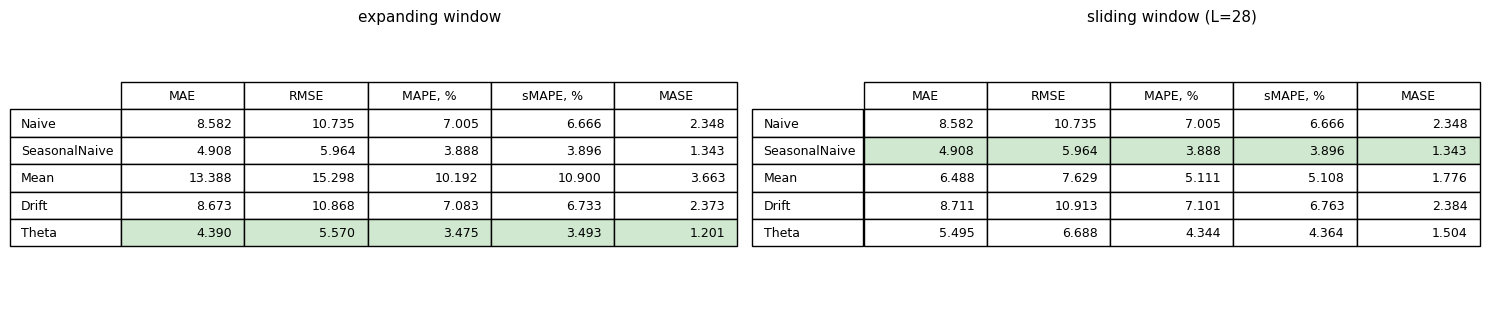

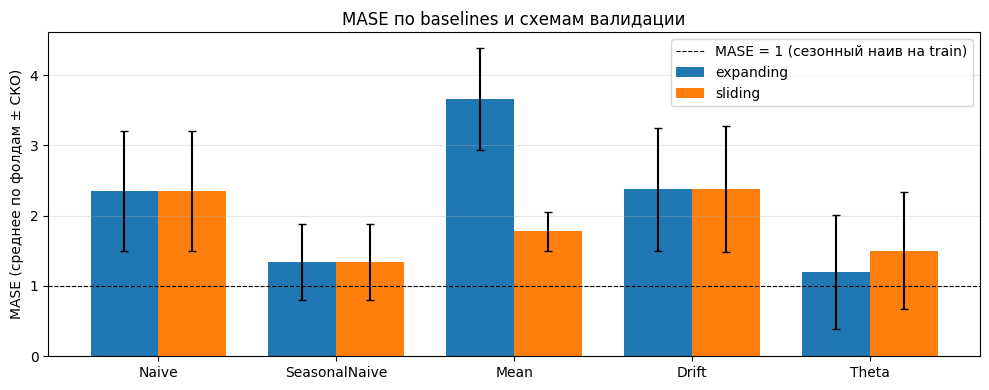

In [ ]:
def draw_table(ax, df, title):
    ax.axis("off"); ax.set_title(title, fontsize=11)
    cells = [[f"{v:.3f}" for v in row] for row in df.to_numpy()]
    tbl = ax.table(cellText=cells, rowLabels=list(df.index), colLabels=list(df.columns), loc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.5)
    best = df.idxmin()
    for j, c in enumerate(df.columns):                    # лучшая модель в каждой колонке подсвечена
        tbl[(list(df.index).index(best[c]) + 1, j)].set_facecolor("#cfe8cf")


fig, axes = plt.subplots(1, 2, figsize=(15, 3.2))
draw_table(axes[0], TAB["expanding"], "expanding window")
draw_table(axes[1], TAB["sliding"], f"sliding window (L={L})")
fig.tight_layout(); plt.show()

names = list(BASELINES)
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38; xs = np.arange(len(names))
for k, sch in enumerate(("expanding", "sliding")):
    m = [fold_frame(RES[sch], lambda t, p: mase(t, p, yv[:FIRST], S))[n].mean() for n in names]
    sd = [fold_frame(RES[sch], lambda t, p: mase(t, p, yv[:FIRST], S))[n].std(ddof=1) for n in names]
    ax.bar(xs + (k - 0.5) * w, m, w, yerr=sd, capsize=3, label=sch)
ax.axhline(1.0, color="k", ls="--", lw=0.8, label="MASE = 1 (сезонный наив на train)")
ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_ylabel("MASE (среднее по фолдам ± СКО)")
ax.set_title("MASE по baselines и схемам валидации"); ax.legend(); ax.grid(alpha=0.3, axis="y")
fig.tight_layout(); plt.show()

## 6. Интервалы для Seasonal Naive (эмпирические квантили остатков backtesting)

Идея: ошибки сезонного наива на **прошлых** фолдах показывают, какого разброса ждать от следующего прогноза. Чтобы не было утечки, остатки собираем на отдельном калибровочном backtesting по данным **до** первого тестового фолда (`y[:FIRST]`, origin с 60-го дня через $H$), а покрытие проверяем на 10 тестовых фолдах, которые в калибровке не участвовали.

Интервал уровня $c$: $[\hat y + q_{(1-c)/2},\ \hat y + q_{(1+c)/2}]$, где $q$ эмпирические квантили калибровочных остатков $e=y-\hat y$. Метрики: **coverage** (доля фактов внутри интервала, должна быть близка к $c$) и **width** (средняя ширина).

In [ ]:
sn = BASELINES["SeasonalNaive"]
cal_origins = list(range(60, FIRST - H + 1, H))
cal_folds = backtest(yv, sn, H=H, scheme="expanding", origins=cal_origins)
cal_res = np.concatenate([f["test"] - f["pred"] for f in cal_folds])
assert cal_origins[-1] + H <= FIRST            # калибровка целиком раньше теста
print(f"калибровка: {len(cal_folds)} фолдов, {len(cal_res)} остатков, среднее = {cal_res.mean():.2f}, СКО = {cal_res.std(ddof=1):.2f}")

test_folds = RES["expanding"]["SeasonalNaive"]
T = np.concatenate([f["test"] for f in test_folds]); P = np.concatenate([f["pred"] for f in test_folds])
rows, cover_fold = [], {}
for c in (0.80, 0.90, 0.95):
    lo_q, hi_q = np.quantile(cal_res, [(1 - c) / 2, (1 + c) / 2])
    lo, hi = P + lo_q, P + hi_q
    inside = (T >= lo) & (T <= hi)
    cover_fold[c] = [float(np.mean((f["test"] >= f["pred"] + lo_q) & (f["test"] <= f["pred"] + hi_q))) for f in test_folds]
    rows.append({"номинал": c, "coverage": inside.mean(), "отклонение": inside.mean() - c,
                 "биномиальная SE": np.sqrt(c * (1 - c) / len(T)), "width": float(np.mean(hi - lo)), "q_low": lo_q, "q_high": hi_q})
INT = pd.DataFrame(rows).set_index("номинал")
display(INT.round(3))
print(f"тестовых точек: {len(T)}. Биномиальная SE занижена: дни внутри недели автокоррелированы (AR(1)), эффективная выборка меньше 70")

# почему покрытие может быть ниже номинала: волатильность ошибок сезонного наива меняется от блока к блоку
e7 = yv[S:] - yv[:-S]                                   # ошибки сезонного наива «на один сезон назад»
blk = [float(np.sqrt(np.mean(e7[len(e7) - 70 * (k + 1): len(e7) - 70 * k] ** 2))) for k in range(10)][::-1]
sd_theory = float(np.sqrt(2 * SIG ** 2 / (1 - PHI ** 2) * (1 - PHI ** S) + 2 * NOISE_STD ** 2))
print("RMSE ошибок SN по 70-дневным блокам (последний блок = тест):", np.round(blk, 2))
print(f"СКО калибровочных остатков = {cal_res.std(ddof=1):.2f}, RMSE на тесте = {rmse(T, P):.2f}, теоретическое СКО для этого процесса = {sd_theory:.2f}")

калибровка: 85 фолдов, 595 остатков, среднее = 0.32, СКО = 4.64


,coverage,отклонение,биномиальная SE,width,q_low,q_high
номинал,,,,,,
0.80,0.671,-0.129,0.048,11.731,-5.424,6.307
0.90,0.843,-0.057,0.036,15.831,-7.625,8.206
0.95,0.871,-0.079,0.026,18.945,-9.186,9.759


тестовых точек: 70. Биномиальная SE занижена: дни внутри недели автокоррелированы (AR(1)), эффективная выборка меньше 70
RMSE ошибок SN по 70-дневным блокам (последний блок = тест): [4.98 4.18 4.75 5.62 4.48 5.35 3.79 3.78 4.92 5.96]
СКО калибровочных остатков = 4.64, RMSE на тесте = 5.96, теоретическое СКО для этого процесса = 5.06


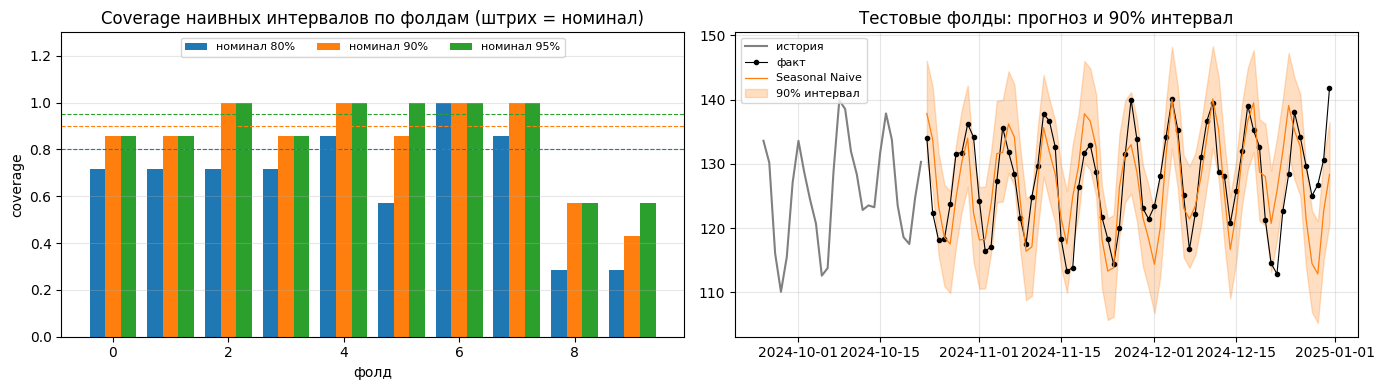

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
wbar = 0.27
for k, c in enumerate(cover_fold):
    ax.bar(np.arange(K) + (k - 1) * wbar, cover_fold[c], wbar, label=f"номинал {c:.0%}")
    ax.axhline(c, color=f"C{k}", ls="--", lw=0.8)
ax.set_xlabel("фолд"); ax.set_ylabel("coverage"); ax.set_ylim(0, 1.3)
ax.set_title("Coverage наивных интервалов по фолдам (штрих = номинал)"); ax.legend(loc="upper center", ncol=3, fontsize=8); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
q_lo, q_hi = np.quantile(cal_res, [0.05, 0.95])
dates = idx[FIRST:N]
ax.plot(idx[FIRST - 28:FIRST], yv[FIRST - 28:FIRST], color="gray", label="история")
ax.plot(dates, T, "k.-", lw=0.8, label="факт")
ax.plot(dates, P, "C1-", lw=0.9, label="Seasonal Naive")
ax.fill_between(dates, P + q_lo, P + q_hi, color="C1", alpha=0.25, label="90% интервал")
ax.set_title("Тестовые фолды: прогноз и 90% интервал"); ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 7. Диагностика утечек: случайный split

Классическая ошибка: перемешать наблюдения и разбить на train/test случайно. Для временных рядов это даёт утечку: соседние дни в train содержат информацию о тестовом дне (автокорреляция), а значение тестового дня попадает в train как лаг-признак для следующих строк.

Эксперимент. Четыре модели из `sklearn`, признаки двух видов:

- «с лагами»: лаги 7..21 (все доступны в момент прогноза на горизонт $H=7$), индекс времени $t$ и день недели;
- «календарь»: только $t$ и день недели.

Каждую модель оцениваем двумя способами:

- **неправильно:** случайный 5-fold (`KFold(shuffle=True)`);
- **правильно:** тот же backtesting, что выше: 10 origins, обучение только на данных до origin.

Сравниваем MAE на **одних и тех же** целевых строках (последние 70 дней). Эталон: Seasonal Naive на тех же строках.

Оговорка: у «календарных» моделей на деревьях при честной оценке добавляется ещё и неумение экстраполировать тренд, поэтому их разрыв смешивает утечку и экстраполяцию. Но вывод для практики тот же: случайный split показывает качество, которого в реальном прогнозе не будет.

In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold

LAGS = list(range(H, H + 15))


def make_xy(y):
    d = pd.DataFrame({"y": np.asarray(y, float)})
    for k in LAGS:
        d[f"lag{k}"] = d["y"].shift(k)
    d["t"] = np.arange(len(d)); d["dow"] = np.arange(len(d)) % S
    d = d.dropna().reset_index(drop=True)
    return d.drop(columns="y"), d["y"].to_numpy()


X, Y = make_xy(yv)
tt = X["t"].to_numpy()
last70 = tt >= FIRST
print("строк в таблице признаков:", len(X), "| строк в последних 70 днях:", int(last70.sum()))

lag_cols = [f"lag{k}" for k in LAGS]
MODELS = {   # (фабрика модели, признаки)
    "RF: лаги + t + день недели": (lambda: RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), lag_cols + ["t", "dow"]),
    "GB: лаги + t + день недели": (lambda: GradientBoostingRegressor(random_state=0), lag_cols + ["t", "dow"]),
    "RF: только календарь (t, dow)": (lambda: RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), ["t", "dow"]),
    "GB: только календарь (t, dow)": (lambda: GradientBoostingRegressor(random_state=0), ["t", "dow"]),
}

# эталон: сезонный наив на тех же целевых строках (y_t - y_{t-7})
pred_sn = np.array([yv[int(t) - S] for t in tt])
m_sn = mae(Y[last70], pred_sn[last70])

rows = []
for name, (make, cols) in MODELS.items():
    Xc = X[cols]
    # --- неправильно: случайный split ---
    pred_rand = np.zeros(len(Y))
    for tr_i, te_i in KFold(n_splits=5, shuffle=True, random_state=0).split(Xc):
        pred_rand[te_i] = make().fit(Xc.iloc[tr_i], Y[tr_i]).predict(Xc.iloc[te_i])
    # --- правильно: backtesting, обучение только на данных до origin ---
    pred_bt = np.full(len(Y), np.nan)
    for start in ORIGINS:
        tr_i = np.where(tt < start)[0]; te_i = np.where((tt >= start) & (tt < start + H))[0]
        pred_bt[te_i] = make().fit(Xc.iloc[tr_i], Y[tr_i]).predict(Xc.iloc[te_i])
    m_r, m_b = mae(Y[last70], pred_rand[last70]), mae(Y[last70], pred_bt[last70])
    rows.append({"модель": name, "MAE случайный split": m_r, "MAE backtesting": m_b,
                 "занижение MAE, %": 100 * (m_b - m_r) / m_b,
                 "RMSE случайный split": rmse(Y[last70], pred_rand[last70]), "RMSE backtesting": rmse(Y[last70], pred_bt[last70]),
                 "лучше SN (случайный), %": 100 * (m_sn - m_r) / m_sn, "лучше SN (честно), %": 100 * (m_sn - m_b) / m_sn})
LEAK = pd.DataFrame(rows).set_index("модель")
display(LEAK.round(2))
print(f"эталон: MAE Seasonal Naive на тех же 70 строках = {m_sn:.2f}")

строк в таблице признаков: 709 | строк в последних 70 днях: 70


,MAE случайный split,MAE backtesting,"занижение MAE, %",RMSE случайный split,RMSE backtesting,"лучше SN (случайный), %","лучше SN (честно), %"
модель,,,,,,,
RF: лаги + t + день недели,4.26,4.40,3.13,5.02,5.07,13.16,10.35
GB: лаги + t + день недели,4.06,4.70,13.51,4.90,5.75,17.21,4.27
"RF: только календарь (t, dow)",3.55,4.43,19.90,4.32,5.30,27.68,9.70
"GB: только календарь (t, dow)",2.88,4.66,38.23,3.40,5.70,41.34,5.03


эталон: MAE Seasonal Naive на тех же 70 строках = 4.91


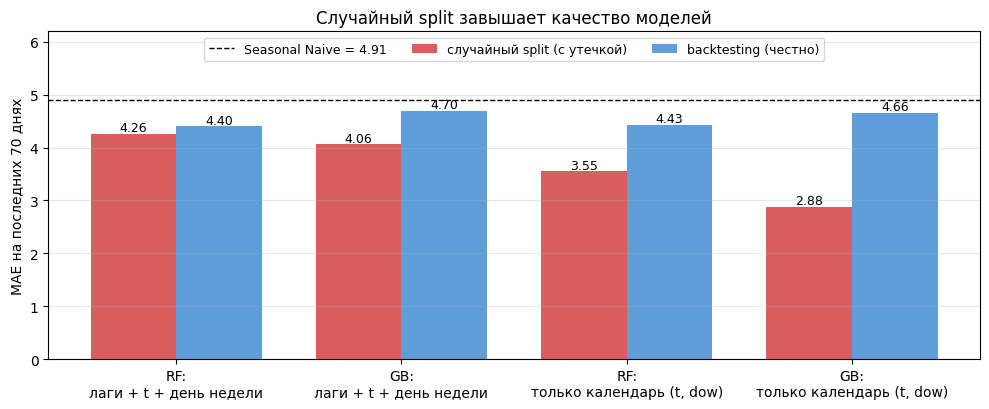

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
xs = np.arange(len(LEAK)); w = 0.38
b1 = ax.bar(xs - w / 2, LEAK["MAE случайный split"], w, color="#d95f5f", label="случайный split (с утечкой)")
b2 = ax.bar(xs + w / 2, LEAK["MAE backtesting"], w, color="#5f9ed9", label="backtesting (честно)")
ax.axhline(m_sn, color="k", ls="--", lw=1, label=f"Seasonal Naive = {m_sn:.2f}")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05, f"{b.get_height():.2f}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels([n.replace(": ", ":\n") for n in LEAK.index])
ax.set_ylabel("MAE на последних 70 днях"); ax.set_title("Случайный split завышает качество моделей")
ax.set_ylim(0, 6.2); ax.legend(loc="upper center", ncol=3, fontsize=9); ax.grid(alpha=0.3, axis="y")
fig.tight_layout(); plt.show()

## 8. Вывод


In [ ]:
for sch, tab in TAB.items():
    b = tab.idxmin()
    print(f"[{sch}] лучший по MASE: {b['MASE']} ({tab.loc[b['MASE'], 'MASE']:.2f}); по MAE: {b['MAE']}; по RMSE: {b['RMSE']}; "
          f"по sMAPE: {b['sMAPE, %']}; по MAPE: {b['MAPE, %']}")
print("интервалы Seasonal Naive (номинал -> coverage, width):",
      {f"{c:.0%}": (round(float(r.coverage), 2), round(float(r.width), 1)) for c, r in INT.iterrows()})
print("утечка, занижение MAE при случайном split, %:", LEAK["занижение MAE, %"].round(0).astype(int).to_dict())

[expanding] лучший по MASE: Theta (1.20); по MAE: Theta; по RMSE: Theta; по sMAPE: Theta; по MAPE: Theta
[sliding] лучший по MASE: SeasonalNaive (1.34); по MAE: SeasonalNaive; по RMSE: SeasonalNaive; по sMAPE: SeasonalNaive; по MAPE: SeasonalNaive
интервалы Seasonal Naive (номинал -> coverage, width): {'80%': (0.67, 11.7), '90%': (0.84, 15.8), '95%': (0.87, 18.9)}
утечка, занижение MAE при случайном split, %: {'RF: лаги + t + день недели': 3, 'GB: лаги + t + день недели': 14, 'RF: только календарь (t, dow)': 20, 'GB: только календарь (t, dow)': 38}


**1. Лучший baseline.** Зависит от схемы валидации.
- **expanding:** лучший Theta (MAE 4,39; RMSE 5,57; MASE 1,20), затем Seasonal Naive (MAE 4,91; MASE 1,34). Оба MASE выше 1: тестовый период шумнее обучающего (см. п. 5), поэтому ошибки на тесте больше, чем у сезонного наива на обучении. Значения стоит сравнивать между моделями: у Theta MASE на 11 % ниже, чем у Seasonal Naive (1,20 против 1,34).
- **sliding (L = 28):** лучший Seasonal Naive (MAE 4,91; MASE 1,34); Theta ухудшается до MAE 5,50 (MASE 1,50); вероятная причина: по 4 неделям (28 точек) сезонные индексы и уровень оцениваются шумно. Mean, наоборот, улучшается с 13,39 до 6,49: короткое окно «забывает» тренд, а среднее по всей истории от текущего уровня сильно отстаёт.
- Naive и Drift (MAE 8,6–8,7) не учитывают недельный цикл и безнадёжно проигрывают, Mean при expanding худший (MAE 13,4).
- Seasonal Naive и Naive от схемы не зависят: используют только последние 7 или 1 точку, поэтому их метрики одинаковы в обеих схемах.

**2. Статистическая оговорка.** Отрыв лидера от второго места невелик: парная разность MAE по фолдам 0,52 ± 0,50 (expanding, Theta против Seasonal Naive) и 0,59 ± 0,47 (sliding, Seasonal Naive против Theta), то есть примерно 1 стандартная ошибка. Theta выигрывает 7 фолдов из 10 при expanding, но уступает Seasonal Naive на фолдах 5 и 9 (на последнем заметно: 10,5 против 8,4). Утверждать «Theta лучше» уверенно нельзя; надёжнее сказать «Theta и Seasonal Naive на одном уровне, остальные baselines заметно хуже». Для твёрдого вывода нужно больше фолдов или длиннее тест.

**3. Какая схема даёт более стабильную оценку.**
- Для моделей, зависящих от окна (Mean, Drift, Theta), разброс MAE по фолдам у обеих схем сопоставим (Theta: СКО 2,96 против 3,02; Drift: 3,21 против 3,28). Исключение Mean: при sliding СКО 1,00 против 2,65 при expanding, потому что среднее по 4 неделям «следит» за уровнем, а среднее по всей истории систематически отстаёт.
- Главное различие не в шуме, а в **смещении оценки и составе лидеров**: sliding меняет победителя (Theta → Seasonal Naive) и поднимает Mean с 5-го места на 3-е. Выбор схемы влияет на вывод сильнее, чем выбор метрики.
- Практическое правило: expanding даёт больше данных для обучения (лучше для моделей, которые что-то оценивают), sliding полезен при нестационарности и смене режима. Окно в 3–4 сезона для Theta мало; для Mean/Drift оно помогает. Схему стоит выбирать так, как модель будет работать в продакшене (переобучение на всей истории или на скользящем окне).
- Оценка по 10 фолдам шумная: CV MAE по фолдам 15–67 %, SE среднего 0,3–1,0.

**4. Согласованность метрик.** Ранжирование моделей одинаково по MAE, RMSE, MAPE, sMAPE и MASE в обеих схемах. Это не случайность:
- MASE считается с общим знаменателем (MAE сезонного наива на `y[:660]`), то есть MASE = MAE / 3,654, ранжирование совпадает с MAE по построению;
- ряд положительный (86–142) и без выбросов, поэтому MAPE и sMAPE ведут себя как нормированный MAE.

Расхождения заметны на уровне отдельных фолдов: лучшая модель по MAE и по RMSE различается в 1 фолде из 10 (expanding) и в 3 из 10 (sliding), потому что RMSE сильнее штрафует единичные большие промахи. MAPE и sMAPE расходятся с MAE на рядах, проходящих через ноль или с сильно меняющимся масштабом; здесь этого нет. MASE полезен тем, что даёт шкалу: значение < 1 означает ошибку меньше, чем у сезонного наива на обучающей части. У нас все MASE > 1 (лучшее значение 1,20), потому что тестовый период шумнее обучающего.

**5. Интервалы Seasonal Naive** (эмпирические квантили остатков калибровочного backtesting на `y[:660]`, 595 остатков):

| номинал | coverage | width |
|---|---|---|
| 80 % | 0,67 | 11,7 |
| 90 % | 0,84 | 15,8 |
| 95 % | 0,87 | 18,9 |

Интервалы **слишком узкие**: покрытие ниже номинала. Причина видна в данных: СКО калибровочных остатков 4,64, а RMSE на тесте 5,96, и тестовый блок оказался самым волатильным из десяти 70-дневных блоков ряда (RMSE по блокам 3,8–5,6, в тесте 5,96; теоретическое значение для этого процесса 5,06). То есть метод сам по себе не сломан, но он предполагает, что распределение ошибок в будущем такое же, как в калибровке, а при 70 тестовых точках с автокорреляцией (биномиальная SE занижена) это сильное допущение. На практике помогают: пересчёт квантилей скользящим образом, больше калибровочных данных, запас по ширине или conformal-подход.

**6. Утечка при случайном split.** На одних и тех же 70 целевых строках случайный split занижает MAE по сравнению с честным backtesting:

| модель | MAE случайный | MAE честно | занижение |
|---|---|---|---|
| RF: лаги + t + dow | 4,26 | 4,40 | 3 % |
| GB: лаги + t + dow | 4,06 | 4,70 | 14 % |
| RF: только календарь | 3,55 | 4,43 | 20 % |
| GB: только календарь | 2,88 | 4,66 | 38 % |

Чем сильнее модель использует соседние во времени точки (индекс времени, плотные деревья), тем больше завышение. Практические последствия: по случайному split GB на календарных признаках «лучше Seasonal Naive на 41 %» и «лучше Theta» (MAE 2,88 против 4,39), по честной оценке выигрыш у Seasonal Naive всего 5 %, а Theta модель проигрывает (4,66 против 4,39). То есть случайный split не только завышает цифры, но и **переворачивает ранжирование**. Ещё источники утечки, которых мы избежали: сезонные индексы или масштаб MASE, посчитанные по всему ряду, подбор гиперпараметров по тесту, нормировка по всему ряду. В ноутбуке каждый train заканчивается строго до origin, а знаменатель MASE считается только по `y[:660]`.

**Итог.** Для этого ряда уверенно выделяются два класса: Theta и Seasonal Naive (MAE около 4,4–5,5) против Naive, Drift и Mean (MAE 6,5–13,4). Выбор между лидерами зависит от схемы валидации и статистически неоднозначен на 10 фолдах; метрики здесь согласованы, а валидация по времени (expanding или sliding) обязательна: случайный split завышает качество на 3–38 % и искажает ранжирование.